# PZ data challenge: results across all task sets

This notebook puts the results of the four task-set notebooks (`pz_challenge_taskset{1..4}_e2e.ipynb`) side by side. It covers all 16 configurations: 4 task sets × 2 sims × 2 depths. It reads what those notebooks wrote to `OUT_DIR` (`outputs/znn` from scratch, `outputs/znn_pretrained_popcosmos` with pre-training, set by `PRETRAINING`; plus the method version `RUN` as a suffix) and trains nothing.

- **Part A, test-set p(z)** (the subtask 1 files): what we submit. The test redshifts are hidden, so this part only shows the predictions, i.e. the implied n(z) and the p(z) widths, set against the training redshift distribution.
- **Part B, held-out scores** (the subtask 2 model files): each `.pkl` is reloaded and run on the same held-out split the task-set notebook used (`train_test_split` with `VAL_FRAC` and `SEED`). The results are scored with the challenge metrics and tiers. Predictions use the same photometric resampling as the submission (`N_SAMPLES` draws). The noise stream is not identical to the e2e run, so the numbers can differ from those notebooks in the last digit.
- **Part C, comparison with a baseline run**: Part B's held-out scores next to those of an earlier run, read from its held-out cache.

The held-out predictions are cached in `CACHE_DIR`, outside `OUT_DIR` so they stay out of the submission tarball. Delete the cache to recompute.

Run this from the repo root with the `qp` conda env as the kernel.

Plot conventions: **colour = depth** (blue 10yr, orange 1yr) and **line style = sim** (solid Cardinal, dashed Flagship).

## Configuration

In [3]:
import znn  # run from the repo root so this picks up the local source

TASKSETS = [1, 2, 3, 4]
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]
TASKSET_NAMES = {
    1: "1: representative",
    2: "2: spec-selected",
    3: "3: spec + COSMOS",
    4: "4: spec + COSMOS, blended",
}

DATA_DIR = "pz_data_challenge/tests/public"
# Which run to read; must match the task-set notebooks: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none):
# "noisytrain_hist" trains each member on its own noise realization and builds histogram p(z)s
RUN = "noisytrain_hist"
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # the submission files written by the task-set notebooks
CACHE_DIR = f"{OUT_DIR}_heldout"  # held-out predictions of part B
PLOT_DIR = "plots"  # figures are saved here, prefixed with the run name so runs never overwrite each other

# must match the task-set notebooks
VAL_FRAC = 0.2
SEED = 42
N_SAMPLES = 50
NOISE_SEED = 42

In [4]:
import itertools
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

CONFIGS = list(itertools.product(TASKSETS, SIMS, SCENARIOS))
COLORS = {"10yr": "#2a78d6", "1yr": "#eb6834"}
LINESTYLES = {"cardinal": "-", "flagship": "--"}
TRAIN_COLOR = "0.6"


def style(sim, scenario):
    return dict(color=COLORS[scenario], ls=LINESTYLES[sim], lw=1.5, label=f"{sim} {scenario}")


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{os.path.basename(OUT_DIR)}_{name}.pdf"), bbox_inches="tight")


def path(kind, taskset, sim, scenario):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    ext = "hdf5" if kind == "pz_estimate" else "pkl"
    return os.path.join(OUT_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.{ext}")


missing = [p for c in CONFIGS for k in ("pz_estimate", "pz_model") if not os.path.exists(p := path(k, *c))]
assert not missing, f"missing submission files: {missing}"

## Reference redshifts

These are the same labels as in the task-set notebooks. Task sets 1 and 2 use `redshift`. Task sets 3 and 4 use `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so scores on the COSMOS-only objects include the label noise.

In [5]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (masks over train).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}

# Part A: test-set p(z)

Each subtask 1 file is a qp ensemble of per-object histograms: all `N_SAMPLES` × members predictions for that object. It is summarised by its `zmode` (the histogram peak, the challenge's point estimate), mean and std, and matched to its test catalogue by `object_id` to pick up the i-band magnitude.

In [6]:
ZGRID = np.linspace(0, 3, 601)  # where the stacked n(z) is evaluated


def read_estimate(taskset, sim, scenario):
    # Per-object summaries of the test-set p(z), and the stacked n(z) (mean p(z)) on ZGRID.
    pz = qp.read(path("pz_estimate", taskset, sim, scenario))
    est = pd.DataFrame(
        {
            "object_id": np.squeeze(pz.ancil["object_id"]),
            "zmode": np.squeeze(pz.ancil["zmode"]),
            "mean": np.squeeze(pz.mean()),
            "std": np.squeeze(pz.std()),
        }
    )
    test = znn.read_catalog(path("test", taskset, sim, scenario), columns=["object_id", "mag_i_lsst"])
    est = est.merge(test, on="object_id", how="left", validate="one_to_one")
    assert est["mag_i_lsst"].notna().all()
    return est, pz.pdf(ZGRID).mean(axis=0)


estimates, stacked_nz, train_z = {}, {}, {}
for c in CONFIGS:
    estimates[c], stacked_nz[c] = read_estimate(*c)
    train = znn.read_catalog(path("training", *c))
    train_z[c], _ = reference_redshifts(train)

summary = pd.DataFrame(
    {
        c: {
            "N test": len(e),
            "median zmode": e["zmode"].median(),
            "median σ": e["std"].median(),
            "median σ/(1+z)": (e["std"] / (1 + e["zmode"])).median(),
            # predictions below the first histogram edge (z < 0) are counted in the first bin
            "frac zmode in first bin": (e["zmode"] < znn.DEFAULT_Z_BINS[1]).mean(),
            "median i (test)": e["mag_i_lsst"].median(),
        }
        for c, e in estimates.items()
    }
).T
summary.index.names = ["taskset", "sim", "scenario"]
summary.round(4)

N test  median z  median σ  median σ/(1+z)  \
taskset sim      scenario                                                
1       cardinal 1yr       20000.0    0.5525    0.0205          0.0131   
                 10yr      20000.0    0.5490    0.0134          0.0086   
        flagship 1yr       20000.0    0.5764    0.0225          0.0140   
                 10yr      20000.0    0.5775    0.0127          0.0080   
2       cardinal 1yr       20000.0    0.8176    0.1361          0.0706   
                 10yr      20000.0    0.7985    0.0704          0.0362   
        flagship 1yr       20000.0    0.8928    0.1475          0.0733   
                 10yr      20000.0    0.9056    0.0684          0.0320   
3       cardinal 1yr       20000.0    0.7702    0.0935          0.0499   
                 10yr      20000.0    0.7697    0.0528          0.0277   
        flagship 1yr       20000.0    0.8778    0.0971          0.0490   
                 10yr      20000.0    0.8851    0.0534          0.0261   
4       cardinal 1yr       20000.0    0.7742    0.0926          0.0501   
                 10yr      20000.0    0.7605    0.0550          0.0293   
        flagship 1yr       20000.0    0.9050    0.1127          0.0569   
                 10yr      20000.0    0.8920    0.0591          0.0292   

                           frac z < 0  frac mass at z < 0  median i (test)  
taskset sim      scenario                                                   
1       cardinal 1yr              0.0              0.0004          22.1072  
                 10yr             0.0              0.0000          22.0959  
        flagship 1yr              0.0              0.0006          22.1419  
                 10yr             0.0              0.0000          22.1341  
2       cardinal 1yr              0.0              0.0046          24.2720  
                 10yr             0.0              0.0052          24.4045  
        flagship 1yr              0.0              0.0074          24.3710  
                 10yr             0.0              0.0067          24.4985  
3       cardinal 1yr              0.0              0.0009          24.2496  
                 10yr             0.0              0.0006          24.3529  
        flagship 1yr              0.0              0.0012          24.3351  
                 10yr             0.0              0.0011          24.4402  
4       cardinal 1yr              0.0              0.0008          24.2115  
                 10yr             0.0              0.0006          24.3100  
        flagship 1yr              0.0              0.0018          24.4588  
                 10yr             0.0              0.0011          24.4251

### Implied n(z) of the test set

The stacked test-set p(z) (the mean of the per-object histograms) against the training reference redshifts (grey, 10yr file). Task set 1 should agree with training. For task sets 2–4 the test set is fainter than the training set, so any difference between the two shows how far the model has to extrapolate.

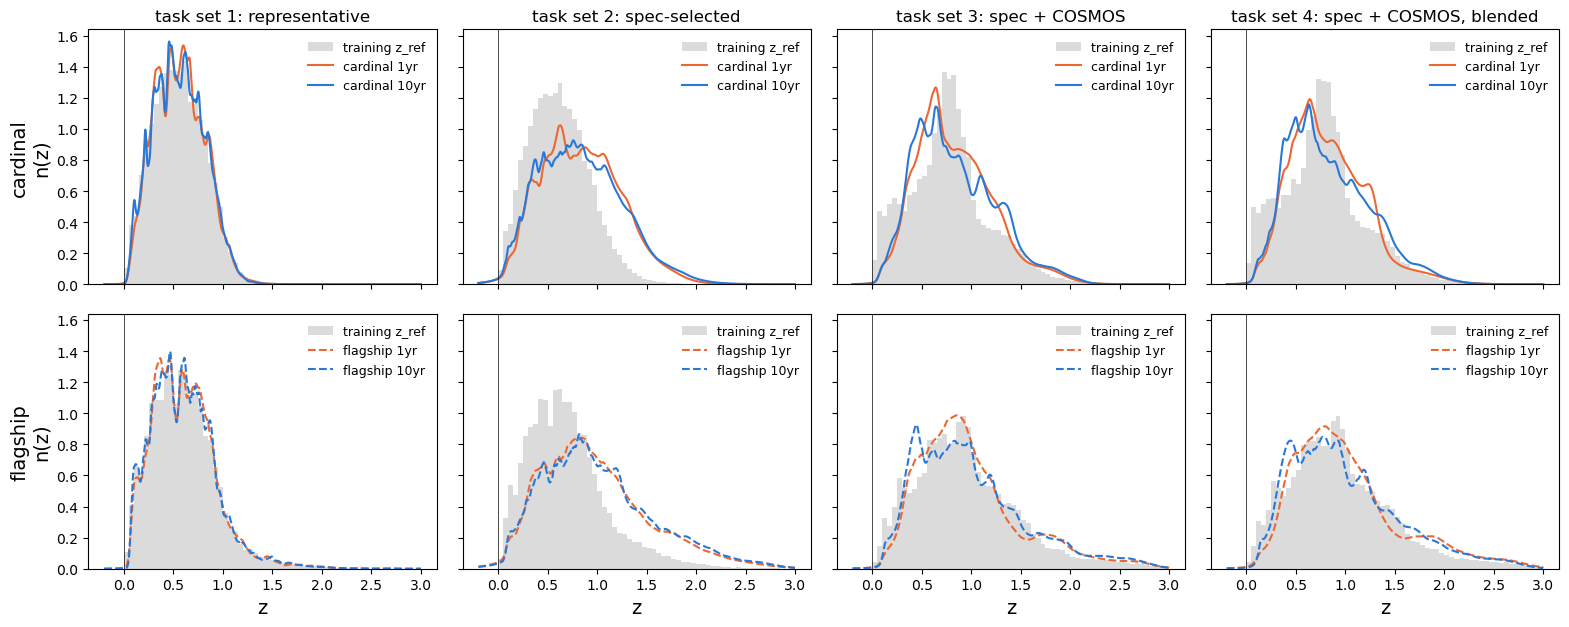

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True, sharey=True)
for col, taskset in enumerate(TASKSETS):
    for row, sim in enumerate(SIMS):
        ax = axes[row, col]
        ax.hist(train_z[(taskset, sim, "10yr")], bins=np.linspace(0, 3, 61), density=True,
                histtype="stepfilled", color=TRAIN_COLOR, alpha=0.35, label="training z_ref")
        for scenario in SCENARIOS:
            ax.plot(ZGRID, stacked_nz[(taskset, sim, scenario)], **style(sim, scenario))
        ax.axvline(0, color="k", lw=0.5)
        if row == 0:
            ax.set_title(f"task set {TASKSET_NAMES[taskset]}", fontsize=12)
        if row == 1:
            ax.set_xlabel("z")
        if col == 0:
            ax.set_ylabel(f"{sim}\nn(z)")
        ax.legend(fontsize=9, frameon=False)
fig.tight_layout()
save(fig, "nz")
plt.show()

# Part B: held-out scores

For each configuration the model file is reloaded and run on the held-out 20% of the training file. The model was trained on the other 80%, the same split as in the task-set notebooks. Each held-out set is scored on all of its objects and on the subsets the task-set notebook reported: task set 2 has `i > 23`, the faintest objects available, and task sets 3 and 4 have spec-selected and COSMOS-only.

Only task set 1 has a held-out set that is representative of its test set. For the other task sets these scores are **optimistic** for the test set.

In [8]:
def heldout_predictions(taskset, sim, scenario):
    # Held-out reference z, i-mag, subset masks, zmode, and the ensemble's histogram p(z) under "pz".
    # Cached in CACHE_DIR: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    stem = os.path.join(CACHE_DIR, f"taskset_{taskset}_{sim}_{scenario}_hist")
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    train = znn.read_catalog(path("training", taskset, sim, scenario))
    z_ref, subsets = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(path("pz_model", taskset, sim, scenario))
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz = znn.ensemble_predict_resampled(
        trained_models, val, errors, N_SAMPLES, np.random.default_rng(NOISE_SEED), **features
    )
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        **{f"subset:{name}": mask[idx_val] for name, mask in subsets.items()},
    }
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


heldout = {}
for c in CONFIGS:
    print("held-out predictions:", *c)
    heldout[c] = heldout_predictions(*c)

held-out predictions: 1 cardinal 1yr
held-out predictions: 1 cardinal 10yr
held-out predictions: 1 flagship 1yr
held-out predictions: 1 flagship 10yr
held-out predictions: 2 cardinal 1yr
held-out predictions: 2 cardinal 10yr
held-out predictions: 2 flagship 1yr
held-out predictions: 2 flagship 10yr
held-out predictions: 3 cardinal 1yr
held-out predictions: 3 cardinal 10yr
held-out predictions: 3 flagship 1yr
held-out predictions: 3 flagship 10yr
held-out predictions: 4 cardinal 1yr
held-out predictions: 4 cardinal 10yr
held-out predictions: 4 flagship 1yr
held-out predictions: 4 flagship 10yr


In [9]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
        # what it is meant to measure, computed directly (not scored)
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
    }, pit.pit_samps


def tier_points(values):
    return {name: sum(lo <= float(values[name]) <= hi for lo, hi in ranges) for name, ranges in scoring.metric_dict.items()}


results, pits = {}, {}
for c, h in heldout.items():
    for key in [k for k in h if k.startswith("subset:")]:
        m = h[key]
        results[(*c, key.removeprefix("subset:"))], pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            h["z_ref"][m], h["zmode"][m], h["pz"][np.flatnonzero(m)]
        )

table = pd.DataFrame(results).T[list(scoring.metric_dict) + ["pit_outlier_direct"]]
table.index.names = ["taskset", "sim", "scenario", "subset"]
points = pd.DataFrame({k: tier_points(v) for k, v in results.items()}).T
points.index.names = table.index.names
points["total"] = points.sum(axis=1)
N_MAX = sum(len(r) for r in scoring.metric_dict.values())
table.round(4)

/home/jaimerzp/anaconda3/envs/qp/lib/python3.13/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/home/jaimerzp/anaconda3/envs/qp/lib/python3.13/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
1       cardinal 1yr      all          0.0018  0.0178            0.0016   
                 10yr     all          0.0007  0.0113            0.0002   
        flagship 1yr      all          0.0004  0.0199            0.0012   
                 10yr     all         -0.0002  0.0117            0.0000   
2       cardinal 1yr      all          0.0038  0.0233            0.0088   
                          i > 23       0.0035  0.0385            0.0221   
                 10yr     all          0.0015  0.0138            0.0005   
                          i > 23       0.0001  0.0186            0.0011   
        flagship 1yr      all          0.0004  0.0265            0.0070   
                          i > 23      -0.0032  0.0406            0.0164   
                 10yr     all          0.0002  0.0146            0.0001   
                          i > 23      -0.0019  0.0186            0.0003   
3       cardinal 1yr      all          0.0049  0.0274            0.0530   
                          spec         0.0049  0.0181            0.0173   
                          COSMOS-only  0.0113  0.0900            0.1199   
                 10yr     all          0.0034  0.0187            0.0264   
                          spec         0.0029  0.0130            0.0012   
                          COSMOS-only  0.0075  0.0479            0.0702   
        flagship 1yr      all          0.0006  0.0390            0.0848   
                          spec         0.0002  0.0214            0.0036   
                          COSMOS-only  0.0063  0.0998            0.1590   
                 10yr     all          0.0036  0.0271            0.0438   
                          spec         0.0028  0.0149            0.0002   
                          COSMOS-only  0.0069  0.0515            0.0798   
4       cardinal 1yr      all          0.0050  0.0311            0.0544   
                          spec         0.0048  0.0203            0.0225   
                          COSMOS-only  0.0095  0.0871            0.1160   
                 10yr     all          0.0023  0.0191            0.0290   
                          spec         0.0019  0.0133            0.0061   
                          COSMOS-only  0.0055  0.0476            0.0707   
        flagship 1yr      all          0.0029  0.0410            0.0872   
                          spec         0.0023  0.0222            0.0050   
                          COSMOS-only  0.0088  0.0998            0.1600   
                 10yr     all          0.0005  0.0283            0.0506   
                          spec         0.0002  0.0155            0.0020   
                          COSMOS-only  0.0022  0.0555            0.0912   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
1       cardinal 1yr      all           60.0568  1.040000e-02  0.0872   
                 10yr     all           33.1502  2.500000e-03  0.0664   
        flagship 1yr      all           49.9918  9.300000e-03  0.0766   
                 10yr     all           67.6786  3.000000e-02  0.0848   
2       cardinal 1yr      all           94.0360  1.010000e-02  0.1001   
                          i > 23         8.8041  6.700000e-03  0.0590   
                 10yr     all           52.6316  3.300000e-03  0.0780   
                          i > 23         2.4784  1.100000e-03  0.0341   
        flagship 1yr      all           50.3089  1.810000e-02  0.0774   
                          i > 23        11.2220  8.100000e-03  0.0595   
                 10yr     all           73.5690  3.750000e-02  0.0933   
                          i > 23        16.7437  2.300000e-03  0.0761   
3       cardinal 1yr      all          197.6412  6.000000e-02  0.1518   
                          spec         147.2119  1.050000e-02  0.1585   
                      

### Points against the challenge tiers

There is one point per nested range a metric falls inside, so at most 3 per metric and 21 per configuration (`pz_data_challenge.scoring.metric_dict`). The table uses the `all` held-out subset.

A 0 under `outlier` is usually not a real failure. qp computes that metric from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1, so compare with `pit_outlier_direct` in the table above. The challenge evaluator makes the same call, so these are the points it would award.

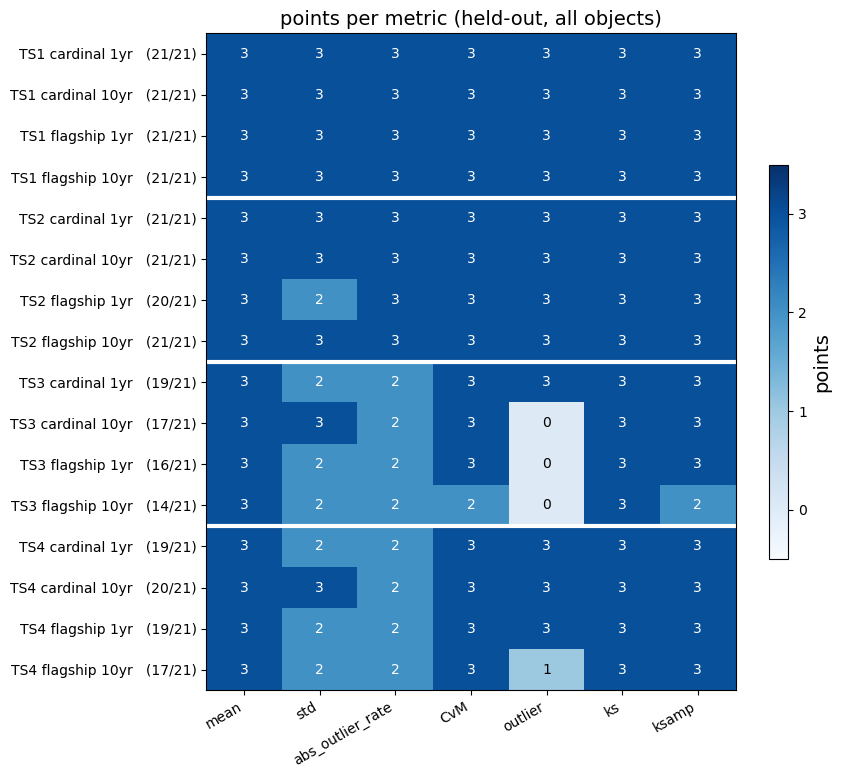

total points per task set (sum over its 4 configurations, held-out all):
taskset
1    84
2    83
3    66
4    75 
(out of 84 each)


In [10]:
pts_all = points.xs("all", level="subset")
labels = [f"TS{t} {s} {y}" for t, s, y in pts_all.index]
metrics = list(scoring.metric_dict)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(pts_all[metrics].to_numpy(), cmap="Blues", vmin=-0.5, vmax=3.5, aspect="auto")
for (i, j), v in np.ndenumerate(pts_all[metrics].to_numpy()):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=10, color="white" if v >= 2 else "black")
ax.set_xticks(range(len(metrics)), metrics, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), [f"{l}   ({t}/{N_MAX})" for l, t in zip(labels, pts_all["total"])])
for y in (3.5, 7.5, 11.5):
    ax.axhline(y, color="white", lw=3)
ax.set_title("points per metric (held-out, all objects)")
fig.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.6, label="points")
fig.tight_layout()
save(fig, "points")
plt.show()

print("total points per task set (sum over its 4 configurations, held-out all):")
print(pts_all["total"].groupby(level="taskset").sum().to_string(), f"\n(out of {4 * N_MAX} each)")

### Subsets

These are the same metrics on the task-set-specific subsets. Task set 2's `i > 23` subset is the closest proxy for its faint test set. In task sets 3 and 4, `COSMOS-only` is the faint, test-like part, scored against noisy many-band labels.

In [11]:
sub = table.drop(index="all", level="subset")
sub_points = points.drop(index="all", level="subset")["total"].rename(f"points (/{N_MAX})")
pd.concat([sub, sub_points], axis=1).round(4)

mean     std  abs_outlier_rate  \
taskset sim      scenario subset                                          
2       cardinal 1yr      i > 23       0.0035  0.0385            0.0221   
                 10yr     i > 23       0.0001  0.0186            0.0011   
        flagship 1yr      i > 23      -0.0032  0.0406            0.0164   
                 10yr     i > 23      -0.0019  0.0186            0.0003   
3       cardinal 1yr      spec         0.0049  0.0181            0.0173   
                          COSMOS-only  0.0113  0.0900            0.1199   
                 10yr     spec         0.0029  0.0130            0.0012   
                          COSMOS-only  0.0075  0.0479            0.0702   
        flagship 1yr      spec         0.0002  0.0214            0.0036   
                          COSMOS-only  0.0063  0.0998            0.1590   
                 10yr     spec         0.0028  0.0149            0.0002   
                          COSMOS-only  0.0069  0.0515            0.0798   
4       cardinal 1yr      spec         0.0048  0.0203            0.0225   
                          COSMOS-only  0.0095  0.0871            0.1160   
                 10yr     spec         0.0019  0.0133            0.0061   
                          COSMOS-only  0.0055  0.0476            0.0707   
        flagship 1yr      spec         0.0023  0.0222            0.0050   
                          COSMOS-only  0.0088  0.0998            0.1600   
                 10yr     spec         0.0002  0.0155            0.0020   
                          COSMOS-only  0.0022  0.0555            0.0912   

                                            CvM       outlier      ks  \
taskset sim      scenario subset                                        
2       cardinal 1yr      i > 23         8.8041  6.700000e-03  0.0590   
                 10yr     i > 23         2.4784  1.100000e-03  0.0341   
        flagship 1yr      i > 23        11.2220  8.100000e-03  0.0595   
                 10yr     i > 23        16.7437  2.300000e-03  0.0761   
3       cardinal 1yr      spec         147.2119  1.050000e-02  0.1585   
                          COSMOS-only   61.6130  3.857250e+01  0.1539   
                 10yr     spec          76.8311  2.410000e-02  0.1121   
                          COSMOS-only   77.8564 -6.780116e+14  0.1653   
        flagship 1yr      spec          33.6084  2.430000e-02  0.0880   
                          COSMOS-only   93.8817  1.910940e+01  0.1527   
                 10yr     spec         142.4595 -9.637540e+01  0.2039   
                          COSMOS-only  139.2649  3.239126e+03  0.1826   
4       cardinal 1yr      spec         157.6867  2.250000e-02  0.1652   
                          COSMOS-only   70.7898  1.373934e+03  0.1616   
                 10yr     spec          78.5064  3.320000e-02  0.1179   
                          COSMOS-only   56.4265 -4.449872e+08  0.1427   
        flagship 1yr      spec          45.0159  3.480000e-02  0.1052   
                          COSMOS-only  127.4332  4.155000e-01  0.1784   
                 10yr     spec          41.1726 -5.344000e-01  0.1039   
                          COSMOS-only   95.7196 -1.173093e+03  0.1547   

                                          ksamp  pit_outlier_direct  \
taskset sim      scenario subset                                      
2       cardinal 1yr      i > 23        29.5501              0.0056   
                 10yr     i > 23        16.2642              0.0053   
        flagship 1yr      i > 23        54.8371              0.0097   
                 10yr     i > 23        76.2384              0.0067   
3       cardinal 1yr      spec         511.8090              0.0094   
                          COSMOS-only  286.9832              0.0652   
                 10yr     spec         280.2032              0.0210   
                          COSMOS-only  360.5562              0.0889   
        flagship 1yr      spec         192.9906              0.0205   
  

### PIT

PIT histograms on the `all` held-out subset. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide.

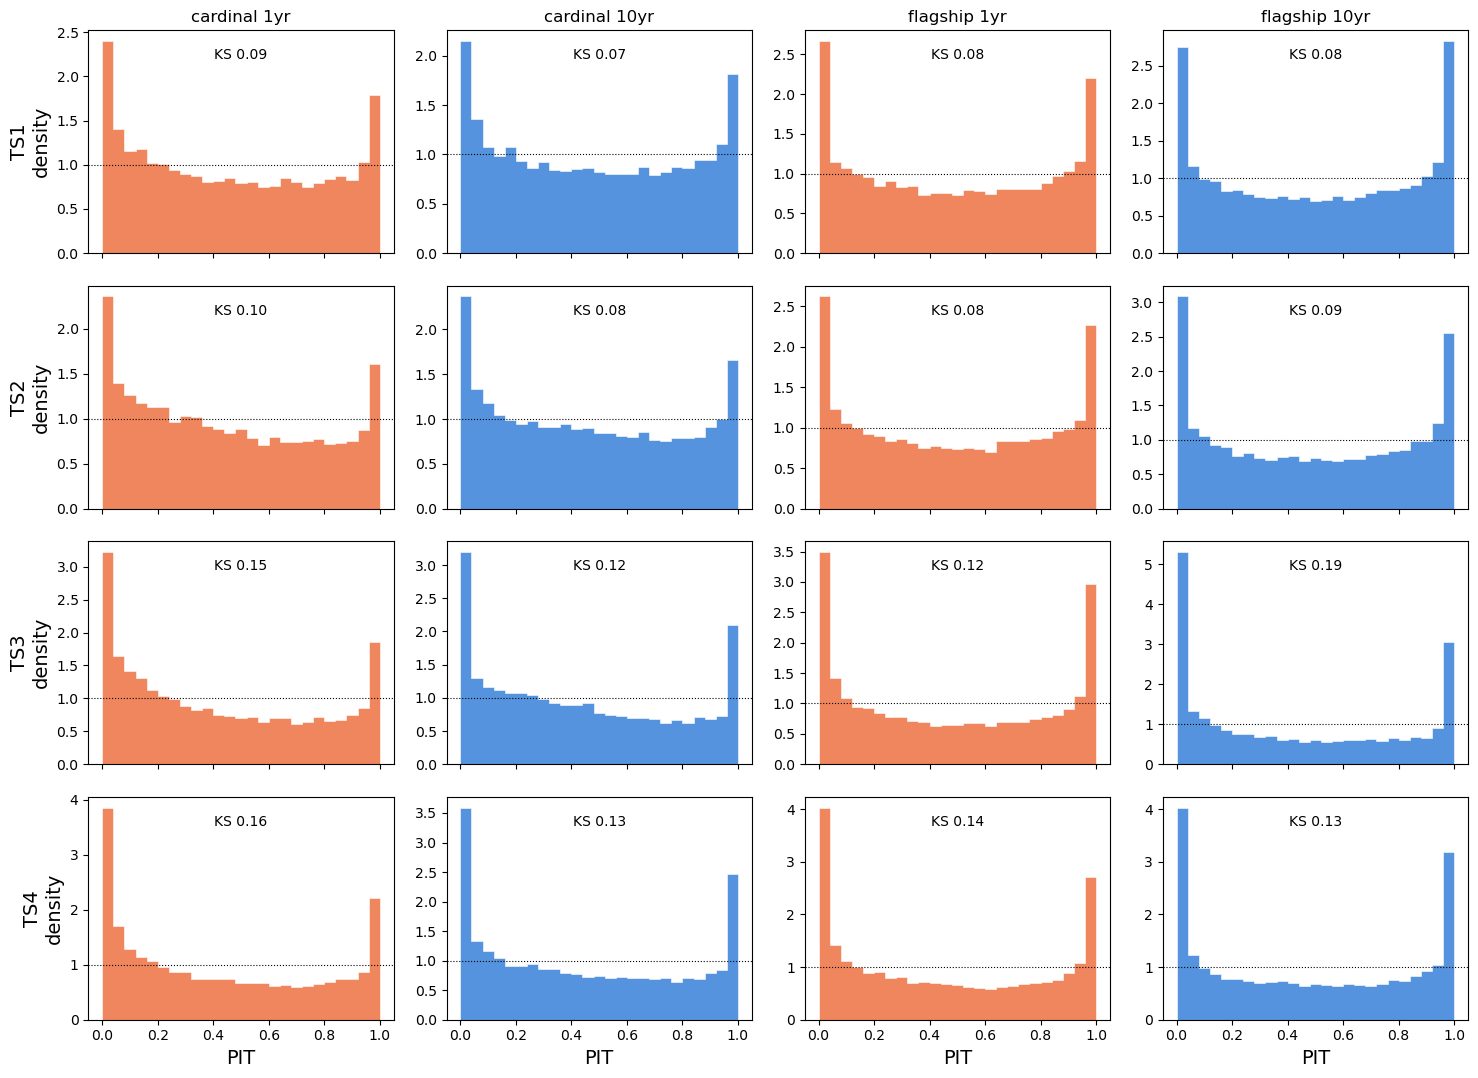

In [12]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        ax.hist(pits[(taskset, sim, scenario, "all")], pit_bins, density=True, color=COLORS[scenario],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks = table.loc[(taskset, sim, scenario, "all"), "ks"]
        ax.text(0.5, 0.92, f"KS {ks:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
fig.tight_layout()
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the `all` held-out subset (log-density 2D histogram). The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

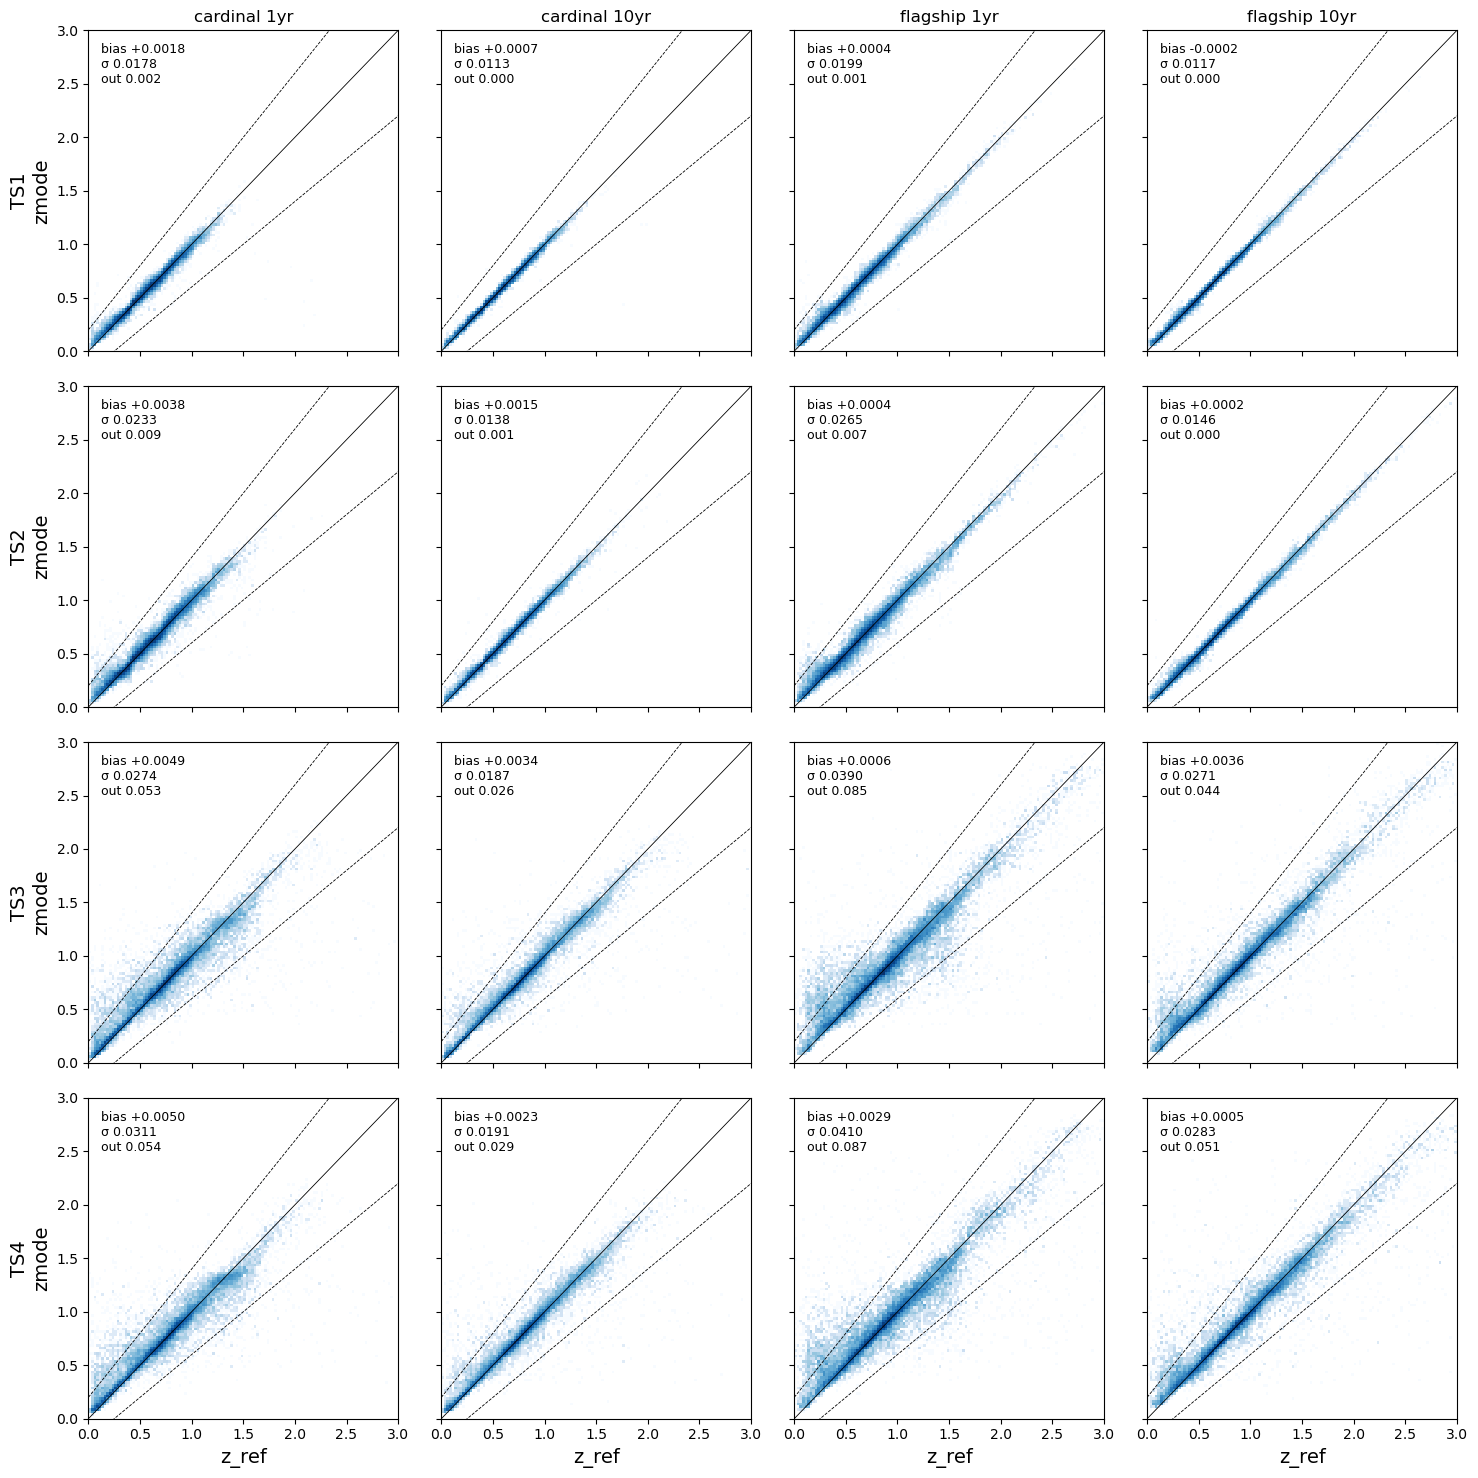

In [13]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
fig, axes = plt.subplots(4, 4, figsize=(15, 15), sharex=True, sharey=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        h = heldout[(taskset, sim, scenario)]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap="Blues", norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[(taskset, sim, scenario, "all")]
        ax.text(0.04, 0.96, f"bias {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        ax.set_xlim(0, 3)
        ax.set_ylim(0, 3)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\nzmode")
        if row == 3:
            ax.set_xlabel("z_ref")
fig.tight_layout()
save(fig, "zphot_vs_zref")
plt.show()

# Part C: comparison with a baseline run

Part B's held-out scores next to those of an earlier run, read from that run's held-out cache. The baseline is the version before `RUN = "noisytrain_hist"`: every member trained on the catalogue photometry as given, and a Gaussian p(z) with the mean and std of the `N_SAMPLES` × members predictions. Its cache holds `z_ref`, `mag_i`, `mean`, `std` and the subset masks per configuration. It is scored here exactly as that version scored it, with the Gaussian mean as the point estimate.

Both runs use the same held-out split (`VAL_FRAC`, `SEED`), so they are scored on the same objects; this is checked.

In [ ]:
# The baseline run: its OUT_DIR, whose held-out cache (<BASELINE_OUT_DIR>_heldout) was written by the
# Gaussian version of this notebook
BASELINE_OUT_DIR = "outputs/znn_pretrained_popcosmos"
BASELINE_LABEL = "baseline"
NEW_LABEL = RUN or "new"
BASELINE_CACHE = f"{BASELINE_OUT_DIR}_heldout"

missing = [p for c in CONFIGS if not os.path.exists(p := os.path.join(BASELINE_CACHE, "taskset_{}_{}_{}.npz".format(*c)))]
assert not missing, f"missing baseline held-out caches: {missing}"

base_results, base_pits = {}, {}
for c in CONFIGS:
    b = dict(np.load(os.path.join(BASELINE_CACHE, "taskset_{}_{}_{}.npz".format(*c))))
    assert np.array_equal(b["z_ref"], heldout[c]["z_ref"]), f"{c}: the baseline was scored on different held-out objects"
    for key in [k for k in b if k.startswith("subset:")]:
        m = b[key]
        pz = qp.Ensemble(qp.stats.norm, data={"loc": b["mean"][m, None], "scale": b["std"][m, None]})
        base_results[(*c, key.removeprefix("subset:"))], base_pits[(*c, key.removeprefix("subset:"))] = challenge_metrics(
            b["z_ref"][m], b["mean"][m], pz
        )

base_table = pd.DataFrame(base_results).T[table.columns]
base_table.index.names = table.index.names
base_points = pd.DataFrame({k: tier_points(v) for k, v in base_results.items()}).T
base_points.index.names = table.index.names
base_points["total"] = base_points.sum(axis=1)

# metrics side by side on the "all" subset, baseline then new for each metric
comparison = pd.concat({BASELINE_LABEL: base_table, NEW_LABEL: table}, axis=1).xs("all", level="subset")
comparison = comparison.swaplevel(axis=1)[[(m, r) for m in table.columns for r in (BASELINE_LABEL, NEW_LABEL)]]
comparison.round(4)

In [ ]:
# challenge points, per configuration and summed per task set ("all" subset)
pts = pd.DataFrame(
    {
        BASELINE_LABEL: base_points.xs("all", level="subset")["total"],
        NEW_LABEL: points.xs("all", level="subset")["total"],
    }
)
pts["change"] = pts[NEW_LABEL] - pts[BASELINE_LABEL]
print(f"points per configuration (out of {N_MAX}):")
display(pts)
print(f"points per task set (out of {4 * N_MAX}):")
display(pts.groupby(level="taskset").sum())

# every subset, as differences new - baseline: lower is better for |mean|, std, abs_outlier_rate, ks, CvM, ksamp
diff = table[list(scoring.metric_dict)] - base_table[list(scoring.metric_dict)]
diff["|mean|"] = table["mean"].abs() - base_table["mean"].abs()
diff["points"] = points["total"] - base_points["total"]
diff.round(4)

In [ ]:
# PIT of the two runs on the "all" held-out subset: baseline outlined in grey, new filled
fig, axes = plt.subplots(4, 4, figsize=(15, 11), sharex=True)
for row, taskset in enumerate(TASKSETS):
    for col, (sim, scenario) in enumerate(itertools.product(SIMS, SCENARIOS)):
        ax = axes[row, col]
        key = (taskset, sim, scenario, "all")
        ax.hist(pits[key], pit_bins, density=True, color=COLORS[scenario], histtype="stepfilled", alpha=0.6,
                label=NEW_LABEL)
        ax.hist(base_pits[key], pit_bins, density=True, color="0.3", histtype="step", lw=1.2, label=BASELINE_LABEL)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.text(0.5, 0.92, f"KS {base_table.loc[key, 'ks']:.2f} → {table.loc[key, 'ks']:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=10)
        if row == 0:
            ax.set_title(f"{sim} {scenario}", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"TS{taskset}\ndensity")
        if row == 3:
            ax.set_xlabel("PIT")
axes[0, 0].legend(fontsize=9, frameon=False, loc="lower center")
fig.tight_layout()
save(fig, "pit_vs_baseline")
plt.show()

# Appendix: what the CNN sees

The model does not take the band magnitudes as a list. Each magnitude (minus the reference i band) is spread over wavelength with its filter curve, and the result is averaged into `n_bins` equal-width wavelength bins. This gives a continuous curve (channel 0 of `X`), which is shown here for a few held-out galaxies across redshift.

- **Left:** the encoding of the catalogue photometry, drawn through the `n_bins` bin centres as in `znn.visualize_the_data`. The shaded band is the 16–84% range over `N_DRAWS` photometric resamplings, i.e. the noise the ensemble sees in training and at prediction time. The filter curves are in the strip on top. Bins with no observed band are 0 (and have 0 in the coverage channel).
- **Right:** the predicted p(z) for that galaxy from Part B (the histogram of all its predictions), with the reference redshift as a dashed line.

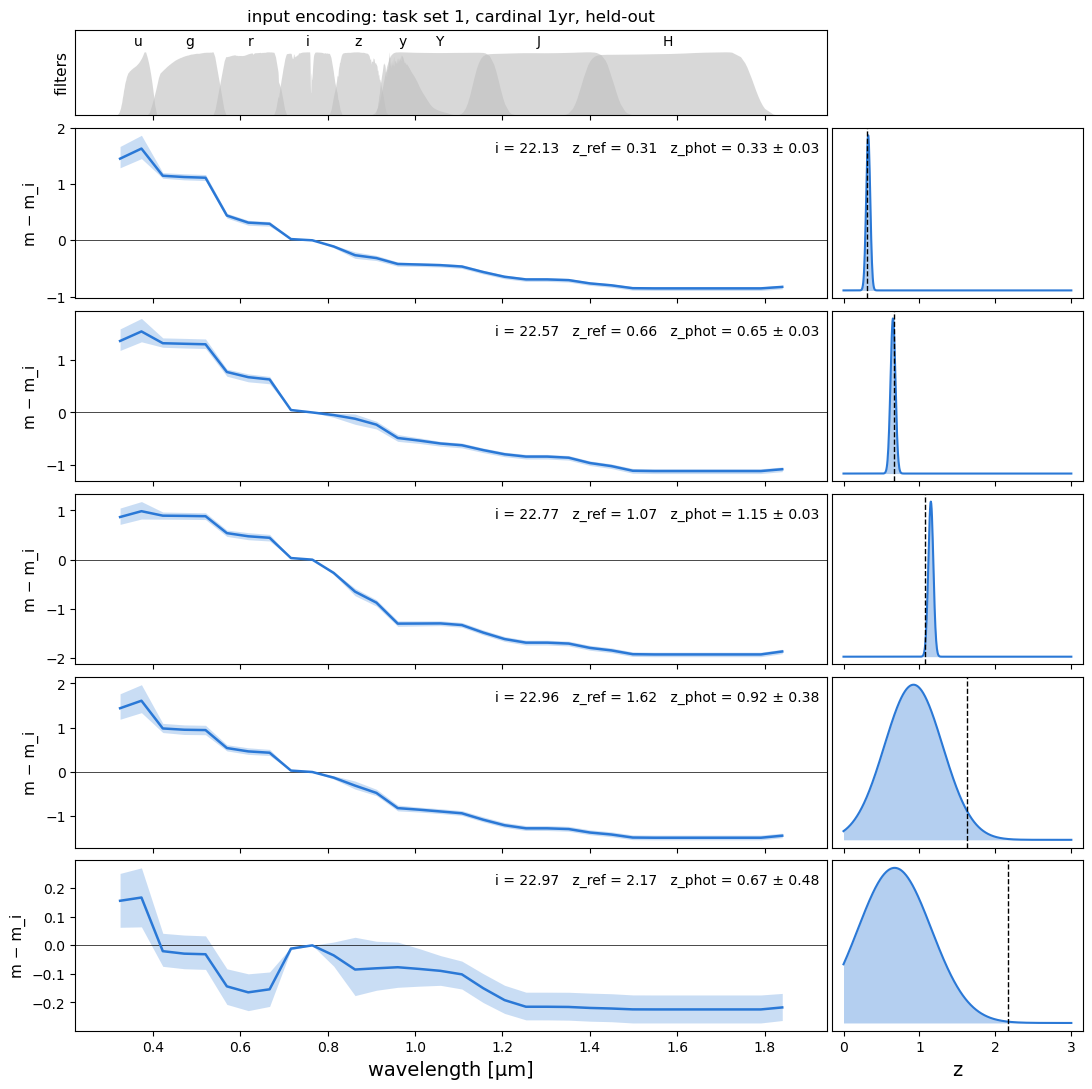

In [16]:
EXAMPLE = (1, "cardinal", "1yr")  # (task set, sim, depth); 1yr makes the photometric errors easier to see
Z_TARGETS = [0.3, 0.7, 1.1, 1.6, 2.2]  # one galaxy picked near each reference redshift
IMAG_RANGE = (22.0, 23.5)  # faint enough for the errors to show
N_DRAWS = 200
rng = np.random.default_rng(1)

train = znn.read_catalog(path("training", *EXAMPLE))
_, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
h = heldout[EXAMPLE]
_, features = znn.load_ensemble_file(path("pz_model", *EXAMPLE))
bands, curves, cfg = features["bands"], features["filter_curves"], features["config"]
errors = {col: f"{col}_err" for col, _ in bands.values()}

in_mag = (h["mag_i"] > IMAG_RANGE[0]) & (h["mag_i"] < IMAG_RANGE[1])
picks = [rng.choice(np.flatnonzero(in_mag & (np.abs(h["z_ref"] - zt) < 0.05))) for zt in Z_TARGETS]
gal = train.iloc[idx_val[picks]]

# wavelength bin centres, as catalog_to_XY builds them
lambda_common = np.linspace(min(c[:, 0].min() for c in curves.values()), max(c[:, 0].max() for c in curves.values()), cfg["n_lambda"])
lam_bins, _ = znn.make_lambda_bins(lambda_common, cfg["n_bins"])
lam_eff = {b: np.sum(c[:, 0] * c[:, 1]) / np.sum(c[:, 1]) for b, c in curves.items()}

X_obs, _ = znn.catalog_to_XY(gal, **features)
enc_draws = [znn.catalog_to_XY(znn.resample_photometry(gal, errors, rng), **features)[0][..., 0] for _ in range(N_DRAWS)]
enc_lo, enc_hi = np.percentile(enc_draws, [16, 84], axis=0)

ENC = "#2a78d6"
um = 1e-4  # filter curves are in Angstrom
fig, axes = plt.subplots(
    len(picks) + 1, 2, figsize=(13, 2.3 * len(picks) + 1.5), sharex="col",
    gridspec_kw=dict(height_ratios=[0.5] + [1] * len(picks), width_ratios=[3, 1], hspace=0.08, wspace=0.01),
)
for b, c in curves.items():
    axes[0, 0].fill_between(c[:, 0] * um, c[:, 1] / c[:, 1].max(), color="0.75", alpha=0.6, lw=0)
    axes[0, 0].text(lam_eff[b] * um, 1.05, b, ha="center", va="bottom", fontsize=10)
axes[0, 0].set_ylim(0, 1.35)
axes[0, 0].set_yticks([])
axes[0, 0].set_ylabel("filters", fontsize=11)
axes[0, 1].axis("off")

for row, (k, j) in enumerate(zip(range(len(picks)), picks), start=1):
    ax = axes[row, 0]
    ax.axhline(0, color="k", lw=0.5)
    ax.fill_between(lam_bins * um, enc_lo[k], enc_hi[k], color=ENC, alpha=0.25, lw=0)
    ax.plot(lam_bins * um, X_obs[k, :, 0], color=ENC, lw=1.8)
    ax.set_ylabel("m − m_i", fontsize=11)
    ax.text(0.99, 0.92, f"i = {h['mag_i'][j]:.2f}   z_ref = {h['z_ref'][j]:.2f}   zmode = {h['zmode'][j]:.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10)

    ax = axes[row, 1]
    pdf = np.squeeze(h["pz"][[j]].pdf(ZGRID))
    ax.fill_between(ZGRID, pdf, color=ENC, alpha=0.35, lw=0)
    ax.plot(ZGRID, pdf, color=ENC, lw=1.5)
    ax.axvline(h["z_ref"][j], color="k", ls="--", lw=1)
    ax.set_yticks([])
axes[-1, 0].set_xlabel("wavelength [μm]")
axes[-1, 1].set_xlabel("z")
axes[0, 0].set_title(f"input encoding: task set {EXAMPLE[0]}, {EXAMPLE[1]} {EXAMPLE[2]}, held-out", fontsize=12)
save(fig, "encoding")
plt.show()